# Trial curves from one outer iteration at a fixed base boundary

**Question.** At one base boundary, with its J, g, H_GN and D fixed, what curves do the damping trials and the
halving (backtracking) loop build, which of them does the geometry update refuse, and where does a refused curve
cross itself?

**What this notebook does.** It takes the saved base state of one real iteration (case `aphex_twin__c13.3`,
first iteration of `stage_3_damped`, default method) and runs *only* the geometry operations on it:
`c9_lm.solve_proposal` -> `c10_geometry_trial.control_step` -> halve by 0.5 -> `update.trial`.
There is no decreasing-loss check and no `validate`. Every damping trial (x10 each time, 5 trials) is crossed with
every halving (0..7). A wrapper on `update.check` records each curve that C10 builds, so refused curves are drawn too.


In [1]:

import pickle, numpy as np, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from bem_inverse.continuation.geometry import FourierCurve

from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'results').exists())
D = pickle.load(open(ROOT/'results/trial_curves/stage3_first_iteration.pkl', 'rb'))
rows, unit = D['rows'], D['length_unit_m']
print(D['case'], D['stage'], 'base loss', round(D['loss'], 6), '| rows', len(rows), '| length unit (m)', unit)

N = 2048
def pts(c, n=N):
    return FourierCurve(np.asarray(c)).values(n)
base = pts(D['base'])


aphex_twin__c13.3 stage_3_damped base loss 0.026387 | rows 40 | length unit (m) 0.05


## 0. Does the replay reproduce the real loop?

The real run tried damping 1e-3 and halvings 0,1,2,3 on this base (halvings 0-2 refused, 3 built). The replay must give the same step sizes and statuses.

In [2]:

real = D['real_trials']
print('real loop rows        :', [(t['backtrack'], round(t['step_norm_m'], 8), t.get('status') or 'built') for t in real])
mine = [r for r in rows if r['damping_trial'] == 0 and r['backtrack'] < 4]
print('replay (damping trial 0):', [(r['backtrack'], round(r['step_norm'], 8), 'refused' if r['status']=='refused' else 'built') for r in mine])


real loop rows        : [(0, 0.00360495, 'refused'), (1, 0.00180248, 'refused'), (2, 0.00090124, 'refused'), (3, 0.00045062, 'built')]
replay (damping trial 0): [(0, 0.00360495, 'refused'), (1, 0.00180248, 'refused'), (2, 0.00090124, 'refused'), (3, 0.00045062, 'built')]


## 1. Where self-crossing is found
Crossings are found by testing every pair of segments of the curve sampled at 2048 points. They are only for display;
the refusal itself comes from the real C10 check (`reason` below).

In [3]:

def crossings(z):
    a, b = z, np.roll(z, -1)
    d = b - a
    n = len(z)
    out = []
    ax, ay, dx, dy = a.real, a.imag, d.real, d.imag
    for i in range(n):
        den = dx[i]*dy - dy[i]*dx            # cross(d_i, d_j)
        ex, ey = ax - ax[i], ay - ay[i]
        with np.errstate(divide='ignore', invalid='ignore'):
            t = (ex*dy - ey*dx)/den           # along segment i
            u = (ex*dy[i] - ey*dx[i])/den     # along segment j
        ok = (den != 0) & (t >= 0) & (t < 1) & (u >= 0) & (u < 1)
        ok[[(i-1) % n, i, (i+1) % n]] = False
        for j in np.flatnonzero(ok):
            if j > i:
                out.append(a[i] + t[j]*d[i])
    return np.array(out)

for r in rows:
    r['moved'] = pts(r['curves'][0][1]) if r['curves'] else None
    r['cross'] = crossings(r['moved']) if r['moved'] is not None and r['status'] == 'refused' else np.array([])
    r['final'] = pts(r['candidate']) if r.get('candidate') is not None else None
print([(r['damping_trial'], r['backtrack'], len(r['cross'])) for r in rows if r['status'] == 'refused'])


[(0, 0, 2), (0, 1, 2), (0, 2, 2), (1, 0, 2), (1, 1, 2), (1, 2, 2), (2, 0, 2), (2, 1, 2), (2, 2, 2), (3, 0, 2)]


## 2. The base boundary and the zoom window
The trial moves are millimetres on a boundary tens of millimetres across, so each panel below is a zoom. All panels use the *same* window (red box) so they can be compared.

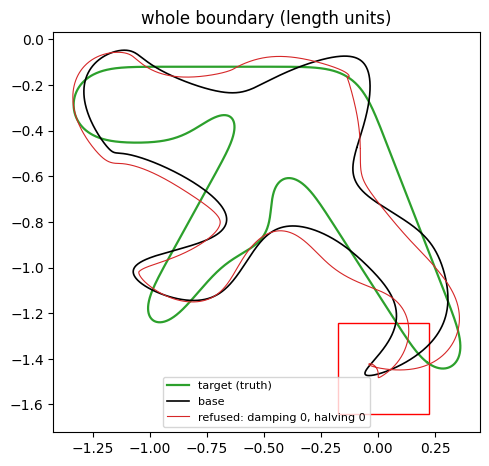

In [4]:

first = next(r for r in rows if r['status'] == 'refused')
centre = first['cross'].mean() if len(first['cross']) else base[np.argmax(abs(first['moved']-base))]
half = 0.2
fig, ax = plt.subplots(figsize=(5.5, 5.5))
from bem_inverse.io import read, curve_from
from experiments.benchmark import campaign as camp
from experiments.cleaned_interface import benchmark as ci
row = next(r for r in camp.descriptors() if r['id'] == D['case'])
target = curve_from(read(ci.ROOT/row['truth'])).values(N)     # truth shape: for display only
ax.plot(target.real, target.imag, color='tab:green', lw=1.6, label='target (truth)')
ax.plot(base.real, base.imag, 'k', lw=1.2, label='base')
ax.plot(first['moved'].real, first['moved'].imag, 'tab:red', lw=.8, label='refused: damping 0, halving 0')
ax.add_patch(Rectangle((centre.real-half, centre.imag-half), 2*half, 2*half, fill=False, ec='red'))
ax.set_aspect('equal'); ax.legend(loc='lower center', fontsize=8); ax.set_title('whole boundary (length units)')
plt.show()


## 3. The grid: damping trial across, halving down
* Grey dashed: base. Coloured line: the curve C10 built at that step.
* Red border: refused by C10 (the first check, `moved_coarse`). The curve is drawn anyway. Red dots: where it crosses itself.
* Green border: built, and passed `moved_coarse`, `moved_fine` and `candidate`. The drawn curve is the final candidate.
* The tag gives the step size (mm); the damping value heads each column.

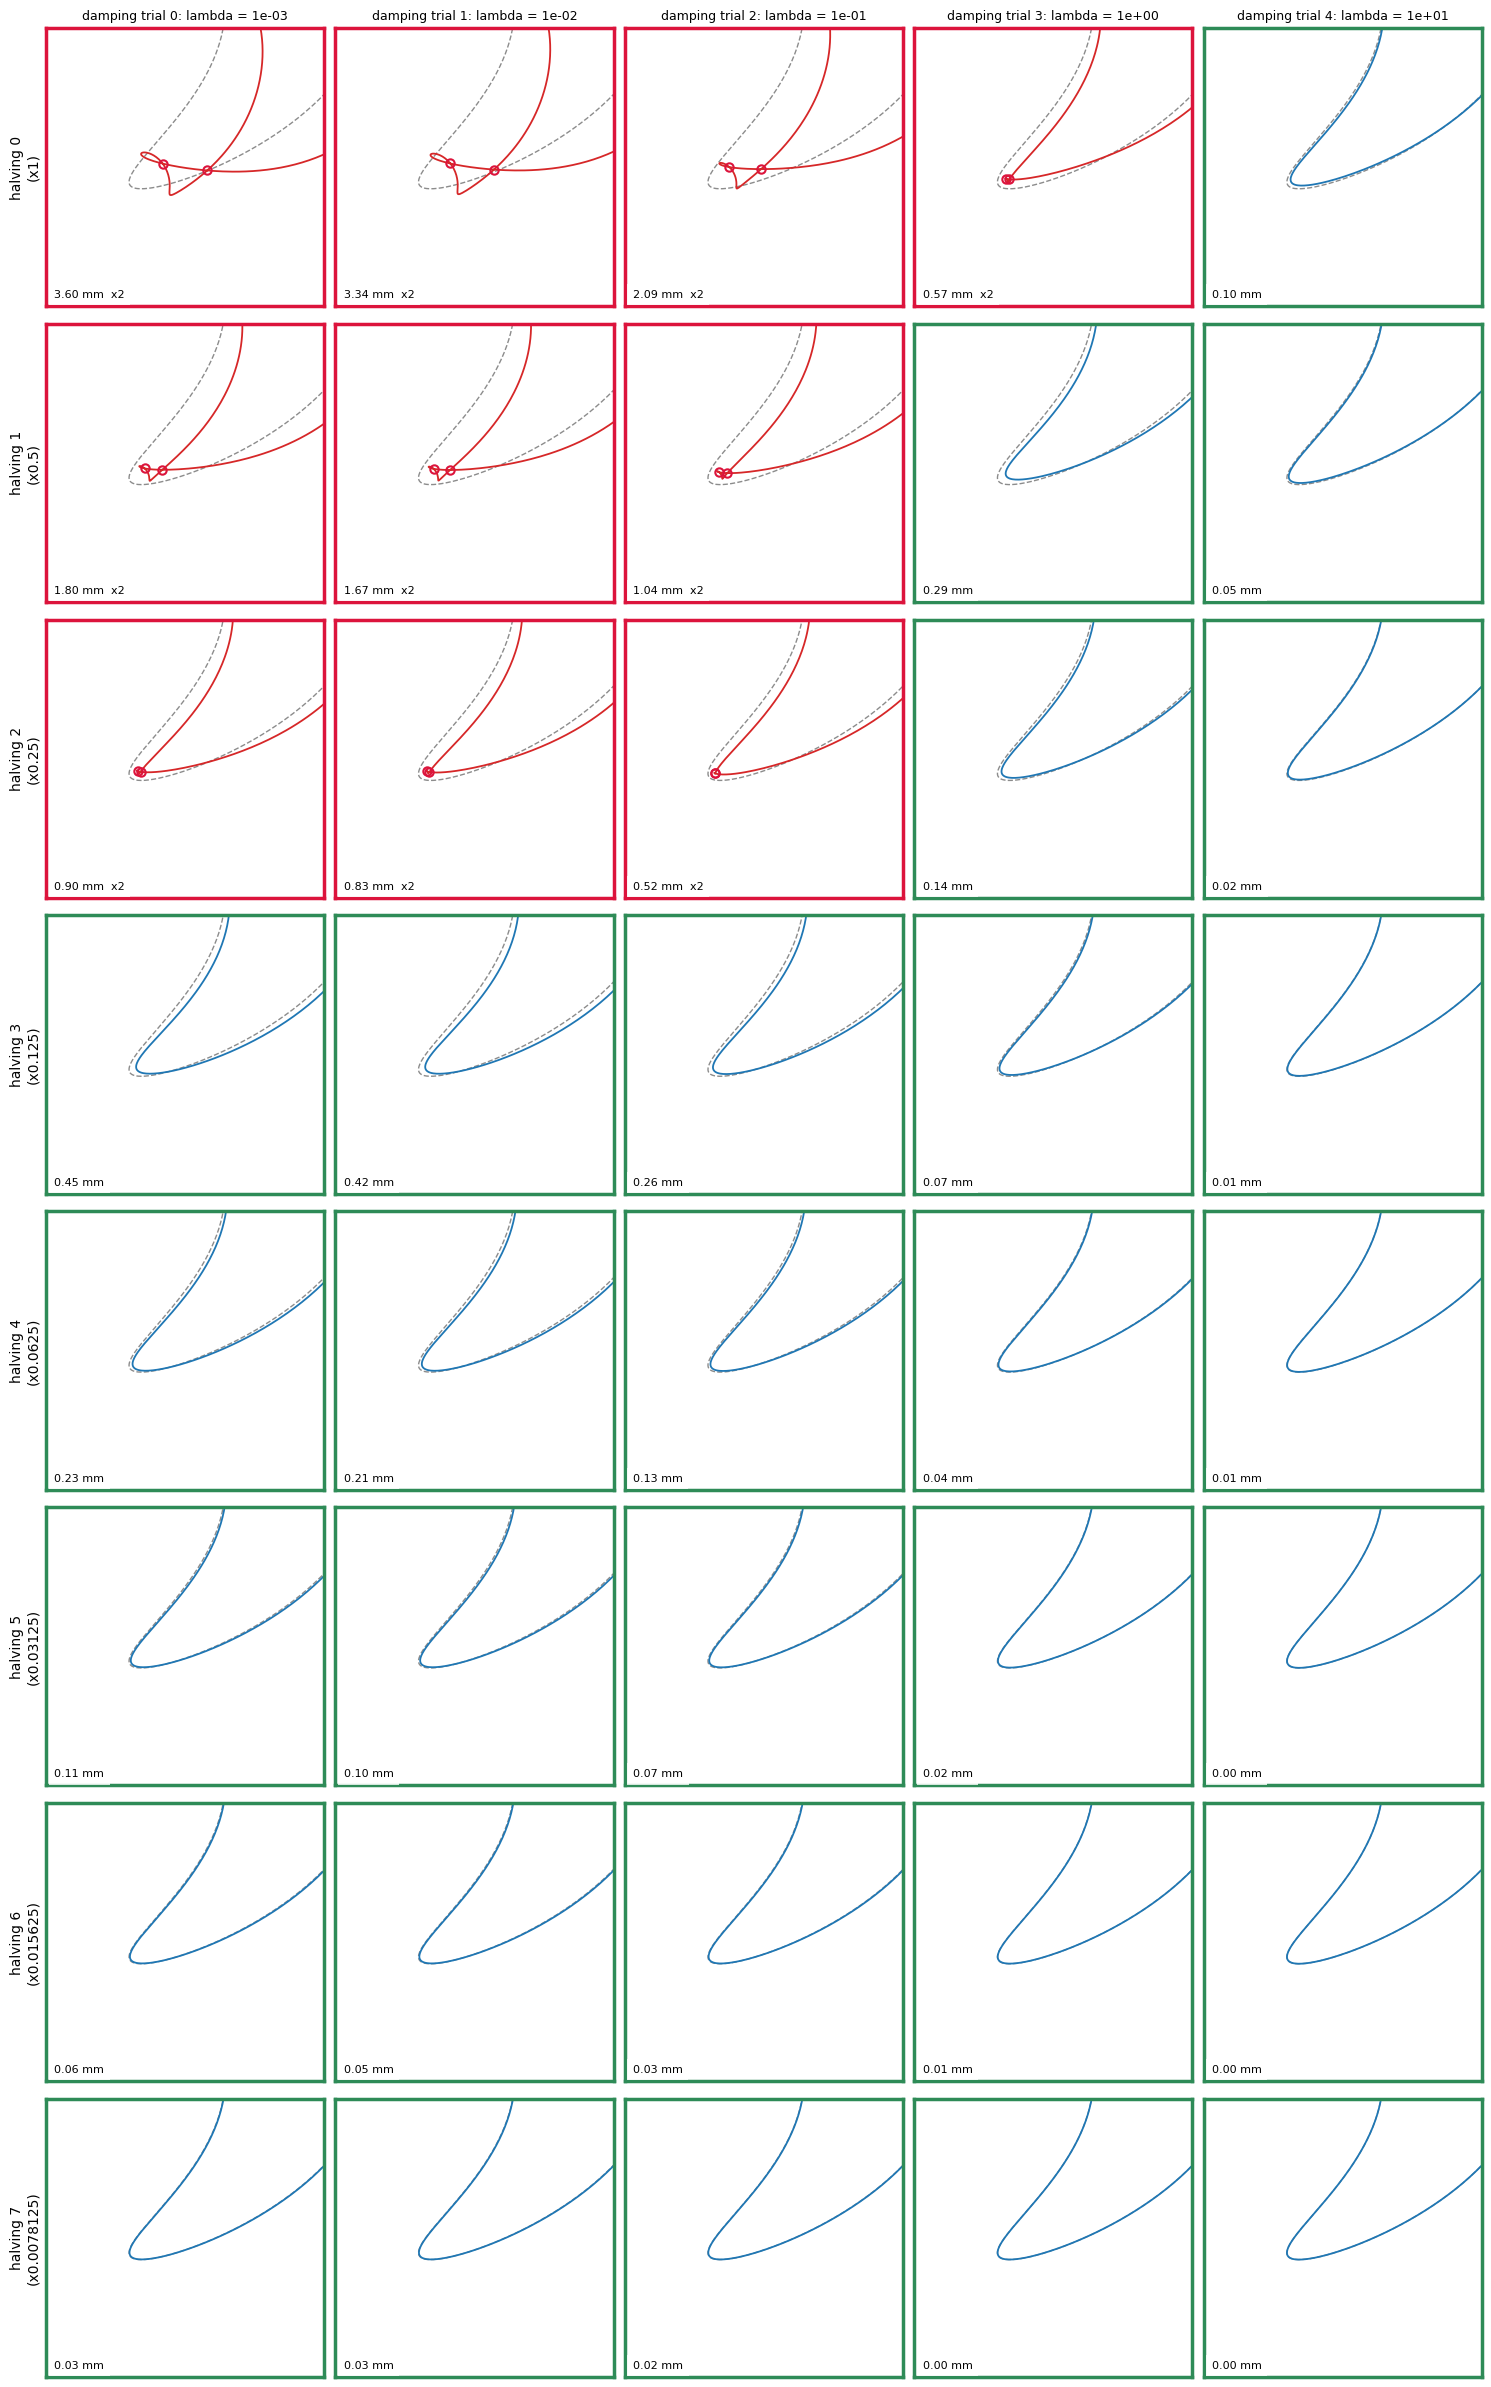

In [5]:

cols = sorted({r['damping_trial'] for r in rows}); backs = sorted({r['backtrack'] for r in rows})
fig, axes = plt.subplots(len(backs), len(cols), figsize=(3.0*len(cols), 3.0*len(backs)), squeeze=False)
for r in rows:
    ax = axes[r['backtrack'], r['damping_trial']]
    z = r['moved'] if r['status'] == 'refused' else r['final']
    ax.plot(base.real, base.imag, color='0.55', ls='--', lw=1)
    refused = r['status'] == 'refused'
    ax.plot(z.real, z.imag, color='tab:red' if refused else 'tab:blue', lw=1.3)
    if len(r['cross']):
        ax.plot(r['cross'].real, r['cross'].imag, 'o', color='crimson', ms=6, mfc='none', mew=1.5)
    ax.set_xlim(centre.real-half, centre.real+half); ax.set_ylim(centre.imag-half, centre.imag+half)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_color('crimson' if refused else 'seagreen'); s.set_linewidth(2.5)
    ax.text(.03, .03, f"{r['step_norm']*1e3:.2f} mm" + (f"  x{len(r['cross'])}" if refused else ''), transform=ax.transAxes, fontsize=8,
            bbox=dict(fc='white', ec='none', alpha=.8))
for c in cols:
    lam = next(r['lam'] for r in rows if r['damping_trial'] == c)
    axes[0, c].set_title(f'damping trial {c}: lambda = {lam:.0e}', fontsize=9)
for b in backs:
    axes[b, 0].set_ylabel(f'halving {b}\n(x{0.5**b:g})')
fig.tight_layout(); plt.show()


## 4. What makes the crossing: displacement along the boundary
Each curve below is the signed normal displacement of the built curve from the base, against the arclength of the base
(damping trial 0, all eight halvings). Refused attempts are red. Vertical ticks mark where the crossings sit.
Halving only rescales this profile; it is the *same* shape each time.

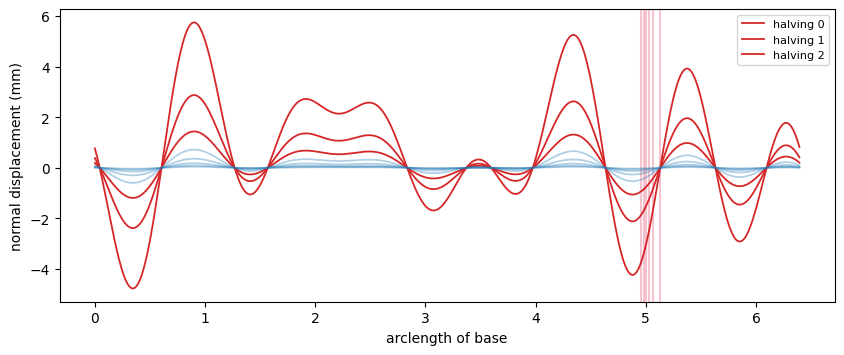

In [6]:

seg = abs(np.diff(base, append=base[0])); s = np.cumsum(seg) - seg
tang = np.gradient(base); nrm = -1j*tang/abs(tang)
fig, ax = plt.subplots(figsize=(10, 3.8))
for r in (r for r in rows if r['damping_trial'] == 0):
    z = r['moved']
    h = ((z - base)*np.conj(nrm)).real*unit*1e3        # mm
    refused = r['status'] == 'refused'
    ax.plot(s, h, color='tab:red' if refused else 'tab:blue', alpha=1 if refused else .35, lw=1.3,
            label=f"halving {r['backtrack']}" if refused else None)
    for x in r['cross']:
        j = np.argmin(abs(base - x)); ax.axvline(s[j], color='crimson', alpha=.25)
ax.set_xlabel('arclength of base'); ax.set_ylabel('normal displacement (mm)'); ax.legend(fontsize=8)
plt.show()


## 5. One damping trial, step by step
The refused curves and the first built one for damping trial 0, overlaid in the same window.

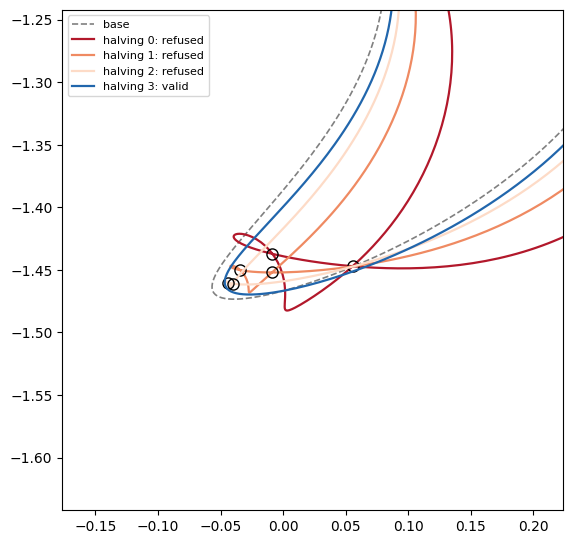

In [7]:

sel = [r for r in rows if r['damping_trial'] == 0 and r['backtrack'] <= 3]
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.plot(base.real, base.imag, color='0.5', ls='--', lw=1.2, label='base')
for r, c in zip(sel, ['#b2182b', '#ef8a62', '#fddbc7', '#2166ac']):
    z = r['moved'] if r['status'] == 'refused' else r['final']
    ax.plot(z.real, z.imag, color=c, lw=1.6, label=f"halving {r['backtrack']}: {r['status']}")
    if len(r['cross']): ax.plot(r['cross'].real, r['cross'].imag, 'o', color=c, mfc='none', mec='k', ms=8)
ax.set_xlim(centre.real-half, centre.real+half); ax.set_ylim(centre.imag-half, centre.imag+half)
ax.set_aspect('equal'); ax.legend(fontsize=8); plt.show()


## 6. Plain Gauss-Newton step on the same base
Same base, same geometry operations, but the step solves H_GN a = -g with no damping (lambda = 0) and a single
damping trial. Halving 0..7 as before. The first row of section 3 (lambda = 1e-3) is the closest LM step for comparison.

step norm (mm), halving 0: plain GN 3.64 | LM lambda=1e-3 3.605
plain GN: [(0, 'refused', 2), (1, 'refused', 2), (2, 'refused', 2), (3, 'valid', 0), (4, 'valid', 0), (5, 'valid', 0), (6, 'valid', 0), (7, 'valid', 0)]


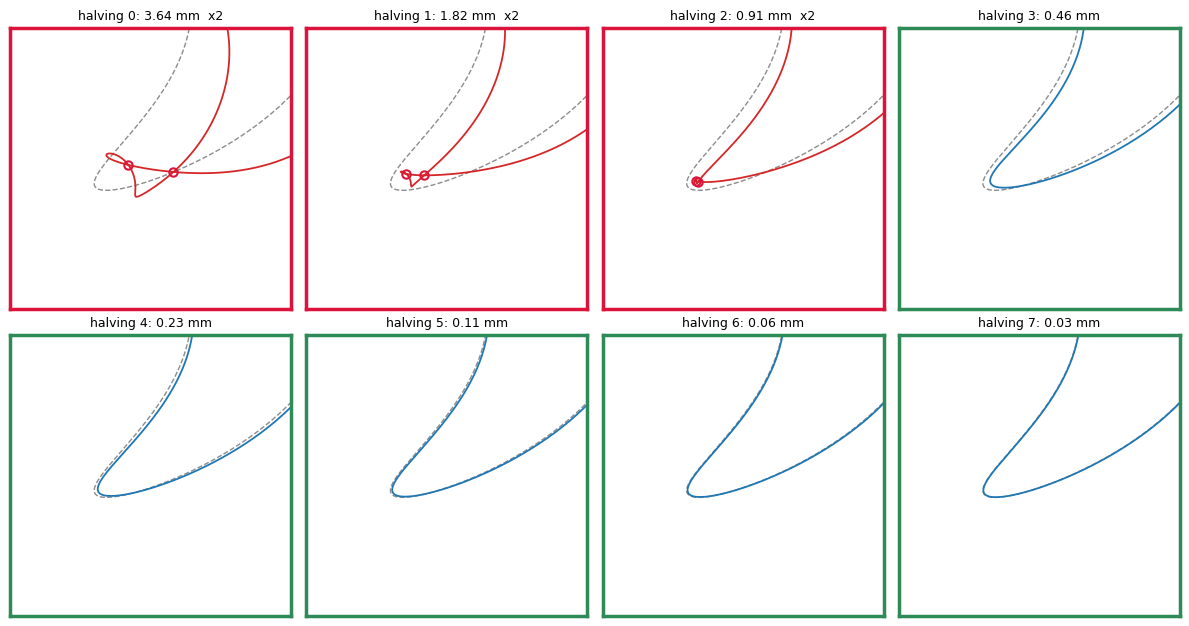

In [8]:

G = pickle.load(open(ROOT/'results/trial_curves/stage3_first_iteration_gn.pkl', 'rb'))
g_rows = G['rows']
for r in g_rows:
    r['moved'] = pts(r['curves'][0][1]) if r['curves'] else None
    r['cross'] = crossings(r['moved']) if r['status'] == 'refused' else np.array([])
    r['final'] = pts(r['candidate']) if r.get('candidate') is not None else None
lm0 = [r for r in rows if r['damping_trial'] == 0]
print('step norm (mm), halving 0: plain GN', round(g_rows[0]['step_norm']*1e3, 3), '| LM lambda=1e-3', round(lm0[0]['step_norm']*1e3, 3))
print('plain GN:', [(r['backtrack'], r['status'], len(r['cross'])) for r in g_rows])
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for r, ax in zip(g_rows, axes.ravel()):
    refused = r['status'] == 'refused'
    z = r['moved'] if refused else r['final']
    ax.plot(base.real, base.imag, color='0.55', ls='--', lw=1)
    ax.plot(z.real, z.imag, color='tab:red' if refused else 'tab:blue', lw=1.3)
    if len(r['cross']): ax.plot(r['cross'].real, r['cross'].imag, 'o', color='crimson', ms=6, mfc='none', mew=1.5)
    ax.set_xlim(centre.real-half, centre.real+half); ax.set_ylim(centre.imag-half, centre.imag+half)
    ax.set_aspect('equal'); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_color('crimson' if refused else 'seagreen'); sp.set_linewidth(2.5)
    ax.set_title(f"halving {r['backtrack']}: {r['step_norm']*1e3:.2f} mm" + (f"  x{len(r['cross'])}" if refused else ''), fontsize=9)
fig.tight_layout(); plt.show()
